# Dirac Operator 고유값 분포

KrylovKit (Arnoldi method)로 **D 자체**의 고유값을 복소 평면에서 계산합니다.

- D는 non-hermitian → 고유값은 **복소수**
- Arnoldi iteration으로 |λ|가 작은 고유값을 반복적으로 계산
- 행렬을 명시적으로 구성하지 않음 (행렬-벡터 곱 D·x만 사용)

In [1]:
using LatticeDiracOperators
using Gaugefields
using LMP
using LinearAlgebra
using Plots
using JLD2
using KrylovKit
using CUDA

NX = 16
NY = 16
NZ = 16
NT = 32
Nwing = 0
NC = 3

params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.15
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 1

Ndof = NC * NX * NY * NZ * NT * 4
println("Lattice: $(NX)×$(NY)×$(NZ)×$(NT), DOF = $Ndof")
println("KrylovKit iterative eigensolver — 행렬 저장 불필요")

[ Info: Precompiling LatticeDiracOperators [019239df-b0e3-486e-8e4c-d1c29ee5d6b9] (cache misses: wrong dep version loaded (2))
[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018] 
┌ Info: Skipping precompilation due to precompilable error. Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
┌ Error: You are using CUDA 13.1.0, but CUDA.jl was precompiled for CUDA 13.0.0.
│ This is unexpected; please file an issue.
└ @ CUDA C:\Users\_s2220186\.julia\packages\CUDA\724Sm\src\initialization.jl:148
[ Info: Threads backend loaded with 1 threads

Lattice: 16×16×16×32, DOF = 1572864
KrylovKit iterative eigensolver — 행렬 저장 불필요


ptimizer


## WilsonFermion ↔ Vector 변환 및 D eigensolver

KrylovKit는 일반 `Vector`에서 동작하므로 WilsonFermion ↔ flat Vector 변환이 필요합니다.

In [2]:
# WilsonFermion → flat Vector{ComplexF64}
function wf_to_vec(x)
    NX=x.NX; NY=x.NY; NZ=x.NZ; NT=x.NT; NC=x.NC; NG=4
    v = Vector{ComplexF64}(undef, NC*NX*NY*NZ*NT*NG)
    idx = 0
    for ig=1:NG, it=1:NT, iz=1:NZ, iy=1:NY, ix=1:NX, ic=1:NC
        idx += 1
        @inbounds v[idx] = x[ic,ix,iy,iz,it,ig]
    end
    return v
end

# flat Vector → WilsonFermion
function vec_to_wf!(x, v)
    NX=x.NX; NY=x.NY; NZ=x.NZ; NT=x.NT; NC=x.NC; NG=4
    idx = 0
    for ig=1:NG, it=1:NT, iz=1:NZ, iy=1:NY, ix=1:NX, ic=1:NC
        idx += 1
        @inbounds x[ic,ix,iy,iz,it,ig] = v[idx]
    end
    return x
end

"""
    compute_D_eigenvalues(D, U, nev; krylovdim, tol)

D의 Re(λ)가 가장 작은 고유값 nev개를 Arnoldi로 계산.
D는 non-hermitian → 고유값은 복소수.
Returns (eigenvalues::Vector{ComplexF64}, eigenvectors)
"""
function compute_D_eigenvalues(D, U, nev::Int;
        krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
    
    x_buf = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    y_buf = similar(x_buf)
    
    # D를 flat vector에 적용
    function D_matvec(v::Vector{ComplexF64})
        vec_to_wf!(x_buf, v)
        mul!(y_buf, D, x_buf)
        return wf_to_vec(y_buf)
    end
    
    Ndof = x_buf.NC * x_buf.NX * x_buf.NY * x_buf.NZ * x_buf.NT * 4
    x0 = randn(ComplexF64, Ndof)
    x0 ./= norm(x0)
    
    # Arnoldi: non-hermitian, :SR = smallest real part
    vals, vecs, info = eigsolve(D_matvec, x0, nev, :SR;
        issymmetric=false, ishermitian=false,
        krylovdim=krylovdim, tol=tol, maxiter=maxiter)
    
    println("KrylovKit: $(info.converged) converged, $(info.numiter) iterations, $(info.numops) matvecs")
    n = min(nev, length(vals))
    return vals[1:n], vecs[1:n]
end

println("Functions defined.")

Functions defined.


## 게이지 설정 로드 및 D 고유값 계산

In [3]:
nev = 50  # 구할 고유값 개수 (|λ| 작은 순서)

# 여러 게이지 배위에서 고유값 수집
gauge_dir = "C:\\Users\\_s2220186\\Desktop\\Julia\\heatbath_ensemble_beta6.0"
gauge_files = [joinpath(gauge_dir, "config_$i.jld2") for i in 0:4]  # 0-indexed
all_evals = Vector{Vector{ComplexF64}}()

for (idx, gfile) in enumerate(gauge_files)
    println("=== Config $idx: $gfile ===")
    # Ug = load(gfile, "U")
    Ug = loadU(gfile)
    U = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)
    
    x = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W = Dirac_operator(U, x, params)
    
    @time evals, _ = compute_D_eigenvalues(D_W, U, nev)
    push!(all_evals, evals)
    
    println("  |λ| 최소 5개: ", round.(abs.(evals[1:min(5,end)]), digits=8))
    println("  λ 최소 5개: ", round.(evals[1:min(5,end)], digits=6))
    println()
end

=== Config 1: C:\Users\_s2220186\Desktop\Julia\heatbath_ensemble_beta6.0\config_0.jld2 ===
KrylovKit: 1 converged, 500 iterations, 24072 matvecs
24078.728576 seconds (25.25 M allocations: 1.928 TiB, 1.28% gc time, 0.02% compilation time: 5% of which was recompilation)


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 1 eigenvalues converged
│ * norm of residuals = (5.87e-10, 2.88e-07, 9.33e-08, 3.01e-07, 1.45e-07, 3.14e-09, 1.41e-07, 4.02e-03, 4.16e-06, 1.34e-05, 6.66e-03, 1.13e-02, 2.46e-04, 1.96e-03, 8.29e-04, 7.03e-03, 5.97e-03, 8.44e-09, 7.60e-08, 1.08e-03, 1.41e-02, 1.58e-06, 4.45e-06, 4.65e-08, 3.13e-08, 2.66e-06, 2.47e-06, 3.18e-03, 8.63e-03, 5.10e-03, 2.15e-04, 1.89e-03, 9.25e-05, 4.64e-08, 3.27e-08, 2.14e-09, 5.83e-09, 4.69e-06, 1.39e-05, 7.67e-03, 2.42e-02, 8.40e-07, 2.04e-06, 8.45e-04, 7.46e-04, 3.26e-03, 1.16e-02, 1.46e-03, 3.55e-04, 1.41e-07)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


  |λ| 최소 5개: [0.39164179, 0.39176058, 0.39176058, 0.39189314, 0.39189314]
  λ 최소 5개: ComplexF64[0.391642 - 0.0im, 0.391733 + 0.004637im, 0.391733 - 0.004637im, 0.391817 + 0.007711im, 0.391817 - 0.007711im]

=== Config 2: C:\Users\_s2220186\Desktop\Julia\heatbath_ensemble_beta6.0\config_1.jld2 ===
KrylovKit: 0 converged, 500 iterations, 24072 matvecs
21597.700674 seconds (1.17 M allocations: 1.927 TiB, 1.19% gc time, 0.00% compilation time)
  |λ| 최소 5개: [0.39172711, 0.39172711, 0.39174929, 0.39232179, 0.39232179]
  λ 최소 5개: ComplexF64[0.391632 - 0.00862im, 0.391632 + 0.00862im, 0.391707 + 0.00575im, 0.391708 + 0.021934im, 0.391708 - 0.021934im]

=== Config 3: C:\Users\_s2220186\Desktop\Julia\heatbath_ensemble_beta6.0\config_2.jld2 ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (3.05e-07, 4.15e-07, 5.68e-05, 7.82e-10, 8.46e-11, 8.45e-05, 8.51e-03, 8.63e-04, 4.24e-04, 4.70e-05, 1.69e-07, 2.24e-07, 2.11e-02, 1.91e-03, 1.99e-03, 3.93e-09, 5.73e-09, 2.38e-02, 1.79e-02, 2.67e-07, 2.09e-07, 6.03e-03, 2.31e-02, 4.51e-05, 1.17e-04, 7.26e-05, 2.94e-04, 1.12e-04, 6.02e-05, 2.84e-07, 2.00e-08, 9.90e-08, 7.00e-07, 5.58e-07, 4.19e-06, 3.66e-02, 2.28e-06, 1.10e-05, 5.09e-04, 5.59e-07, 1.97e-05, 5.99e-05, 2.29e-04, 5.68e-03, 3.55e-07, 1.54e-07, 9.00e-06, 2.03e-04, 1.42e-02, 7.06e-07)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 0 converged, 500 iterations, 24072 matvecs
21431.498070 seconds (1.17 M allocations: 1.927 TiB, 1.17% gc time, 0.00% compilation time)
  |λ| 최소 5개: [0.39174082, 0.39174082, 0.39192499, 0.39192499, 0.39201683]
  λ 최소 5개: ComplexF64[0.391736 + 0.002028im, 0.391736 - 0.002028im, 0.39182 + 0.009092im, 0.39182 - 0.009092im, 0.391982 - 0.005197im]

=== Config 4: C:\Users\_s2220186\Desktop\Julia\heatbath_ensemble_beta6.0\config_3.jld2 ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (1.42e-08, 1.24e-08, 6.12e-08, 9.47e-08, 5.37e-04, 7.83e-05, 2.57e-03, 1.13e-02, 7.11e-05, 8.73e-06, 1.31e-02, 3.77e-03, 1.68e-02, 3.68e-03, 8.43e-10, 3.06e-09, 9.68e-05, 3.40e-05, 1.05e-02, 1.86e-02, 6.21e-07, 5.06e-07, 3.83e-04, 1.14e-04, 1.89e-06, 2.57e-06, 4.67e-06, 1.06e-05, 1.18e-06, 2.10e-07, 9.33e-05, 1.22e-04, 6.89e-05, 2.50e-04, 6.70e-07, 1.18e-06, 3.57e-04, 3.34e-04, 2.16e-08, 5.37e-09, 1.44e-03, 5.53e-03, 5.61e-06, 1.48e-05, 1.10e-02, 2.74e-04, 9.48e-04, 5.30e-06, 7.15e-05, 3.15e-03)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 1 converged, 500 iterations, 24072 matvecs
21303.613284 seconds (1.17 M allocations: 1.927 TiB, 1.17% gc time, 0.00% compilation time)
  |λ| 최소 5개: [0.39143452, 0.39172151, 0.39172151, 0.39201238, 0.39201238]
  λ 최소 5개: ComplexF64[0.391435 + 0.0im, 0.391627 + 0.008589im, 0.391627 - 0.008589im, 0.391737 + 0.014682im, 0.391737 - 0.014682im]

=== Config 5: C:\Users\_s2220186\Desktop\Julia\heatbath_ensemble_beta6.0\config_4.jld2 ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 1 eigenvalues converged
│ * norm of residuals = (6.80e-12, 1.11e-08, 7.20e-09, 1.46e-07, 3.19e-08, 1.49e-06, 6.44e-06, 1.65e-03, 2.64e-03, 7.60e-04, 4.48e-04, 1.35e-05, 7.57e-06, 4.89e-03, 9.27e-05, 7.76e-05, 2.05e-02, 2.58e-03, 2.04e-02, 1.32e-02, 1.09e-10, 1.40e-11, 5.99e-03, 6.71e-03, 8.46e-07, 6.25e-07, 2.92e-03, 9.38e-09, 8.67e-10, 8.85e-08, 3.89e-09, 2.28e-05, 1.98e-05, 7.40e-05, 6.06e-05, 3.56e-04, 4.41e-04, 6.23e-09, 4.46e-09, 6.05e-05, 1.48e-04, 3.35e-02, 2.03e-06, 1.97e-06, 6.05e-02, 2.79e-05, 4.90e-05, 1.34e-02, 8.29e-03, 4.65e-02)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 3 converged, 500 iterations, 23863 matvecs
20506.674815 seconds (1.17 M allocations: 1.922 TiB, 1.24% gc time, 0.00% compilation time)
  |λ| 최소 5개: [0.39097423, 0.39232587, 0.39232587, 0.3920323, 0.39203231]
  λ 최소 5개: ComplexF64[0.390974 + 0.0im, 0.3916 - 0.023849im, 0.3916 + 0.023849im, 0.392027 + 0.00208im, 0.392027 - 0.00208im]



┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 3 eigenvalues converged
│ * norm of residuals = (1.07e-15, 1.63e-14, 2.80e-14, 2.85e-06, 2.73e-06, 3.13e-06, 1.63e-05, 2.38e-07, 4.41e-07, 1.89e-04, 5.33e-04, 4.60e-04, 1.56e-06, 1.45e-06, 2.75e-03, 7.48e-03, 4.02e-03, 7.82e-06, 2.15e-06, 2.95e-03, 1.83e-03, 1.76e-02, 1.32e-05, 4.14e-06, 2.29e-02, 2.32e-03, 1.15e-03, 2.25e-07, 2.10e-06, 1.31e-02, 1.91e-02, 2.36e-03, 6.44e-03, 2.39e-02, 2.42e-08, 6.56e-08, 1.74e-02, 3.85e-10, 4.90e-12, 6.64e-06, 3.71e-06, 5.48e-06, 5.16e-05, 5.85e-08, 1.28e-08, 5.61e-02, 2.88e-03, 8.58e-06, 2.99e-05, 2.57e-03)
│ * number of operations = 23863
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


## D 고유값 분포 — 복소 평면

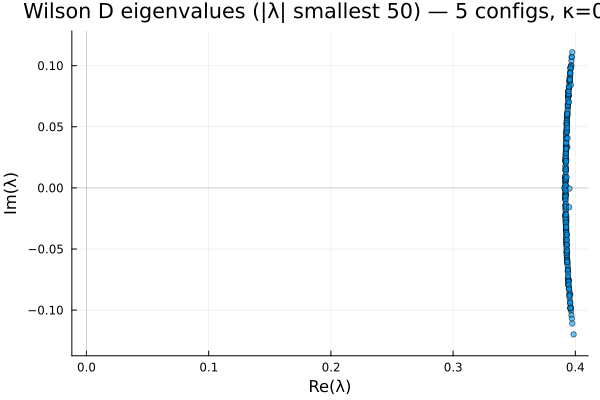

In [4]:
# 모든 config의 D 고유값을 복소 평면에 scatter
all_flat = vcat(all_evals...)

p1 = scatter(real.(all_flat), imag.(all_flat),
    markersize=3, alpha=0.6, legend=false,
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="Wilson D eigenvalues (|λ| smallest $nev) — $(length(gauge_files)) configs, κ=$(params["κ"])",
    aspect_ratio=:equal)
vline!([0], color=:gray, linewidth=1, alpha=0.3)
hline!([0], color=:gray, linewidth=1, alpha=0.3)
display(p1)

## |λ| 분포 히스토그램

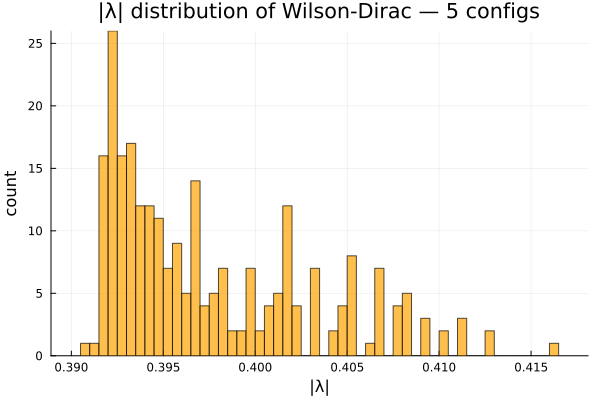

In [5]:
abs_vals = abs.(all_flat)

p2 = histogram(abs_vals, bins=60, alpha=0.7, legend=false, color=:orange,
    xlabel="|λ|", ylabel="count",
    title="|λ| distribution of Wilson-Dirac — $(length(gauge_files)) configs")
display(p2)

## Config별 고유값 비교 (복소 평면)

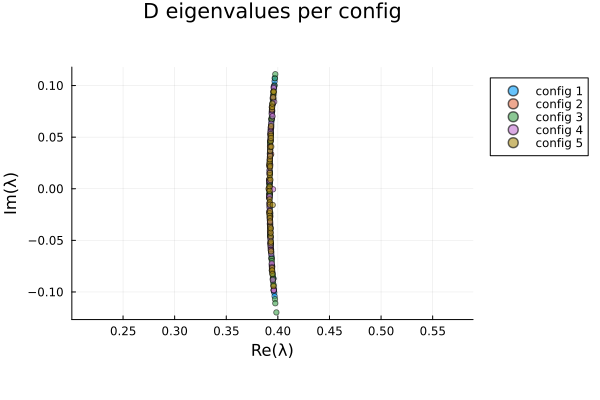

In [6]:
# 각 config의 고유값을 복소 평면에서 비교
p3 = plot(xlabel="Re(λ)", ylabel="Im(λ)",
    title="D eigenvalues per config", legend=:outertopright, aspect_ratio=:equal)
for (i, ev) in enumerate(all_evals)
    scatter!(real.(ev), imag.(ev), markersize=3, alpha=0.6, label="config $i")
end
display(p3)

## Wilson vs Clover 비교

In [7]:
# 1개 config에서 Wilson vs Clover 비교
Ug = load(gauge_files[1], "U")
U_cmp = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
substitute_U!(U_cmp, Ug)

x_cmp = Initialize_pseudofermion_fields(U_cmp[1], "Wilson", nowing=true)
D_W_cmp = Dirac_operator(U_cmp, x_cmp, params)

# Wilson D eigenvalues
println("Wilson D eigenvalues...")
@time evals_wilson, _ = compute_D_eigenvalues(D_W_cmp, U_cmp, nev)

# Clover D eigenvalues
D_cl = CloverDiracOperator(D_W_cmp, U_cmp, 1.0)

x_buf_cl = Initialize_pseudofermion_fields(U_cmp[1], "Wilson", nowing=true)
y_buf_cl = similar(x_buf_cl)

function D_clover_matvec(v::Vector{ComplexF64})
    vec_to_wf!(x_buf_cl, v)
    mul!(y_buf_cl, D_cl, x_buf_cl)
    return wf_to_vec(y_buf_cl)
end

Ndof_c = NC * NX * NY * NZ * NT * 4
x0_c = randn(ComplexF64, Ndof_c); x0_c ./= norm(x0_c)

println("Clover D eigenvalues...")
@time vals_cl, vecs_cl, info_cl = eigsolve(D_clover_matvec, x0_c, nev, :SR;
    issymmetric=false, ishermitian=false,
    krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
evals_clover = vals_cl[1:min(nev, length(vals_cl))]
println("Clover converged: $(info_cl.converged)")

Wilson D eigenvalues...
KrylovKit: 1 converged, 500 iterations, 24072 matvecs
19028.322810 seconds (1.17 M allocations: 1.927 TiB, 1.34% gc time, 0.00% compilation time)


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 1 eigenvalues converged
│ * norm of residuals = (8.23e-09, 8.07e-08, 3.84e-07, 2.27e-07, 5.14e-06, 3.35e-09, 1.18e-07, 6.70e-06, 8.87e-05, 3.44e-04, 4.50e-05, 3.94e-04, 3.70e-03, 2.68e-08, 6.28e-09, 3.54e-04, 2.48e-03, 1.92e-02, 6.20e-03, 1.05e-06, 1.07e-06, 3.36e-07, 4.92e-08, 1.58e-06, 4.65e-07, 2.31e-02, 6.80e-04, 5.47e-03, 1.18e-02, 1.89e-03, 5.23e-04, 1.13e-04, 3.56e-02, 4.20e-07, 2.41e-08, 3.89e-08, 9.99e-10, 1.52e-02, 5.49e-06, 4.80e-04, 2.00e-05, 3.05e-06, 6.43e-03, 1.43e-02, 9.21e-03, 3.91e-03, 4.25e-02, 1.41e-07, 8.01e-06, 2.20e-03)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


Clover D eigenvalues...
19993.957818 seconds (1.42 M allocations: 1.922 TiB, 1.27% gc time, 0.00% compilation time)
Clover converged: 6


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 6 eigenvalues converged
│ * norm of residuals = (6.75e-16, 2.86e-15, 4.47e-15, 7.90e-15, 4.47e-09, 5.68e-09, 1.77e-09, 3.30e-09, 1.14e-09, 3.28e-10, 4.04e-10, 5.45e-16, 4.98e-16, 5.64e-03, 8.21e-10, 5.11e-09, 5.42e-03, 4.00e-04, 3.55e-04, 2.36e-03, 2.93e-03, 9.45e-15, 1.12e-14, 3.05e-07, 4.23e-07, 2.21e-10, 1.58e-10, 1.96e-09, 1.19e-09, 8.24e-03, 2.31e-07, 1.43e-07, 7.09e-03, 1.13e-02, 1.18e-02, 4.73e-02, 1.97e-06, 5.20e-06, 4.98e-02, 8.15e-13, 2.21e-13, 2.50e-13, 4.20e-13, 4.28e-06, 4.72e-07, 2.03e-02, 2.47e-02, 2.40e-07, 8.61e-08, 1.06e-05)
│ * number of operations = 23864
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


## Wilson vs Clover — D 고유값 비교 (복소 평면)

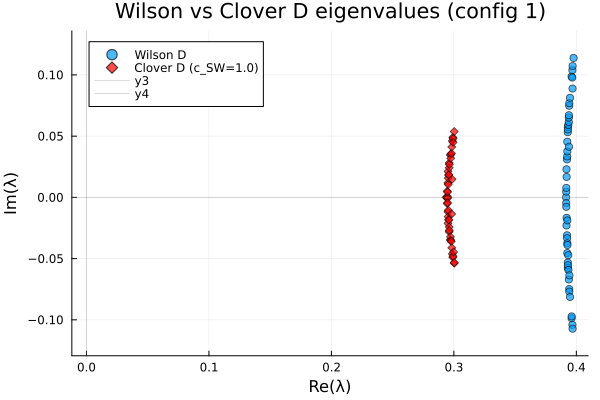

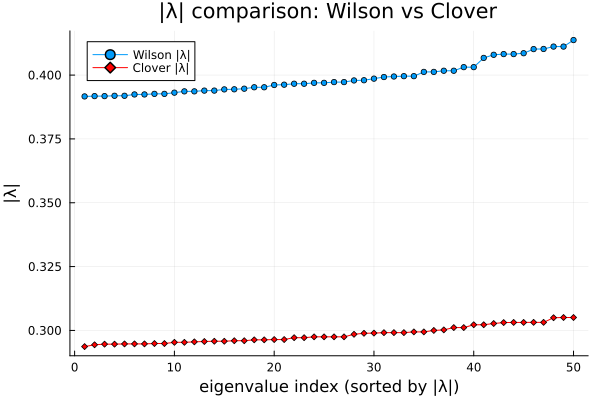

In [8]:
# 복소 평면에서 Wilson vs Clover 비교
p4 = scatter(real.(evals_wilson), imag.(evals_wilson),
    markersize=4, alpha=0.7, label="Wilson D",
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="Wilson vs Clover D eigenvalues (config 1)", aspect_ratio=:equal)
scatter!(real.(evals_clover), imag.(evals_clover),
    markersize=4, alpha=0.7, marker=:diamond, label="Clover D (c_SW=1.0)", color=:red)
vline!([0], color=:gray, linewidth=1, alpha=0.3)
hline!([0], color=:gray, linewidth=1, alpha=0.3)
display(p4)

# |λ| 비교
n_plot = min(length(evals_wilson), length(evals_clover))
abs_w = sort(abs.(evals_wilson[1:n_plot]))
abs_c = sort(abs.(evals_clover[1:n_plot]))
p5 = plot(1:n_plot, abs_w, marker=:circle, markersize=3, label="Wilson |λ|",
    xlabel="eigenvalue index (sorted by |λ|)", ylabel="|λ|",
    title="|λ| comparison: Wilson vs Clover")
plot!(1:n_plot, abs_c, marker=:diamond, markersize=3, label="Clover |λ|", color=:red)
display(p5)

## 통계 요약

In [9]:
_mean(x) = sum(x)/length(x)

println("=" ^ 50)
println("  Eigenvalue Summary ($(NX)×$(NY)×$(NZ)×$(NT) lattice)")
println("=" ^ 50)

println("\n--- Wilson D ($(length(gauge_files)) configs, $(nev) evals each) ---")
abs_all = abs.(all_flat)
println("  최소 |λ|: $(minimum(abs_all))")
println("  평균 최소 |λ|: $(_mean(minimum.(abs.(ev) for ev in all_evals)))")
println("  Re(λ) 범위: [$(minimum(real.(all_flat))), $(maximum(real.(all_flat)))]")
println("  Im(λ) 범위: [$(minimum(imag.(all_flat))), $(maximum(imag.(all_flat)))]")

if @isdefined evals_clover
    abs_cl = abs.(evals_clover)
    println("\n--- Clover D (config 1, c_SW=1.0) ---")
    println("  최소 |λ|: $(minimum(abs_cl))")
    println("  Re(λ) 범위: [$(minimum(real.(evals_clover))), $(maximum(real.(evals_clover)))]")
    println("  Im(λ) 범위: [$(minimum(imag.(evals_clover))), $(maximum(imag.(evals_clover)))]")
end

  Eigenvalue Summary (16×16×16×32 lattice)

--- Wilson D (5 configs, 50 evals each) ---
  최소 |λ|: 0.39097422702240964
  평균 최소 |λ|: 0.3915036938541286
  Re(λ) 범위: [0.39097422702240964, 0.39856696153363214]
  Im(λ) 범위: [-0.11984174540841899, 0.11096468743665164]

--- Clover D (config 1, c_SW=1.0) ---
  최소 |λ|: 0.2936681586865568
  Re(λ) 범위: [0.2936681586865568, 0.3002952912301413]
  Im(λ) 범위: [-0.05375248445072631, 0.05375248457800534]


## Critical κ 추정

LatticeDiracOperators의 Wilson Dirac: $W = 1 - \kappa H$ (H = hopping matrix, κ-independent).

따라서 고유값이 **κ에 선형**: $\lambda(\kappa) = 1 - \kappa h$  
→ $h = (1-\lambda)/\kappa$, 그리고 $\kappa_c = 1/\text{Re}(h)$

**스캔 없이** 한 κ에서의 고유값으로 직접 κ_c를 계산할 수 있음.  
단, `:SR`은 Re(λ) 최소 → κ < 0일 때 **doubler** 쪽. Physical branch는 `:LR` (Re(λ) 최대) 필요.

In [10]:
# `:LR` (largest Re) 고유값도 계산 — physical branch
# 기존 all_evals (`:SR`)은 doubler branch

all_evals_LR = Vector{Vector{ComplexF64}}()

for (idx, gfile) in enumerate(gauge_files)
    println("=== Config $idx (:LR) ===")
    Ug = load(gfile, "U")
    U = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)
    
    x = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W = Dirac_operator(U, x, params)
    
    x_buf = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    y_buf = similar(x_buf)
    
    function D_matvec_lr(v::Vector{ComplexF64})
        vec_to_wf!(x_buf, v)
        mul!(y_buf, D_W, x_buf)
        return wf_to_vec(y_buf)
    end
    
    Ndof = NC * NX * NY * NZ * NT * 4
    x0 = randn(ComplexF64, Ndof); x0 ./= norm(x0)
    
    vals, _, info = eigsolve(D_matvec_lr, x0, nev, :LR;
        issymmetric=false, ishermitian=false,
        krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
    
    n = min(nev, length(vals))
    push!(all_evals_LR, vals[1:n])
    println("  converged=$(info.converged), Re(λ) max 5: ", round.(real.(vals[1:min(5,n)]), digits=4))
end

println("\n:LR eigenvalues computed.")

=== Config 1 (:LR) ===
  converged=1, Re(λ) max 5: [1.6084, 1.6083, 1.6083, 1.6082, 1.6082]
=== Config 2 (:LR) ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 1 eigenvalues converged
│ * norm of residuals = (3.72e-10, 1.34e-07, 3.17e-08, 8.72e-08, 3.22e-07, 1.68e-09, 1.28e-08, 9.03e-06, 6.34e-06, 5.20e-03, 4.37e-03, 6.89e-03, 4.33e-04, 4.42e-05, 2.59e-04, 4.21e-03, 2.53e-09, 3.02e-08, 3.50e-04, 8.23e-04, 1.98e-03, 4.36e-06, 4.17e-07, 1.40e-08, 5.64e-08, 3.77e-07, 6.83e-06, 1.97e-03, 2.43e-03, 7.43e-03, 2.25e-03, 5.87e-05, 2.16e-04, 5.38e-03, 1.75e-07, 3.70e-08, 9.04e-09, 1.89e-09, 5.57e-06, 6.46e-06, 1.45e-02, 1.28e-05, 2.43e-06, 2.08e-03, 3.91e-03, 3.04e-02, 1.72e-02, 1.48e-02, 5.50e-03, 3.57e-03)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


  converged=0, Re(λ) max 5: [1.6084, 1.6084, 1.6083, 1.6083, 1.6083]
=== Config 3 (:LR) ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (1.15e-07, 4.45e-08, 6.97e-11, 1.95e-10, 1.00e-04, 9.63e-06, 1.67e-03, 3.39e-03, 8.00e-03, 5.22e-03, 2.78e-03, 5.41e-04, 5.14e-03, 8.43e-05, 1.38e-04, 2.92e-07, 1.10e-07, 3.00e-03, 3.24e-03, 2.11e-03, 1.48e-08, 2.40e-09, 3.38e-06, 8.14e-08, 5.35e-04, 2.29e-05, 3.44e-05, 3.36e-03, 1.90e-02, 3.15e-05, 8.84e-04, 3.73e-08, 7.95e-07, 3.65e-07, 1.47e-06, 8.32e-06, 3.75e-07, 9.18e-06, 6.92e-06, 1.14e-03, 2.09e-06, 3.53e-05, 3.28e-04, 1.21e-05, 5.33e-02, 8.27e-04, 2.59e-07, 1.76e-08, 1.90e-05, 1.03e-04)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


  converged=0, Re(λ) max 5: [1.6083, 1.6083, 1.6082, 1.6082, 1.608]
=== Config 4 (:LR) ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (1.31e-08, 2.18e-08, 2.88e-08, 1.57e-08, 1.69e-04, 3.63e-04, 4.98e-03, 4.48e-03, 1.91e-06, 1.12e-05, 1.87e-03, 5.20e-03, 1.44e-02, 1.55e-10, 2.20e-10, 2.35e-04, 7.14e-05, 1.31e-02, 1.07e-02, 2.41e-02, 1.92e-02, 4.66e-07, 2.27e-07, 1.25e-04, 7.83e-05, 2.37e-02, 2.65e-06, 1.31e-06, 2.37e-02, 2.58e-05, 3.27e-05, 5.29e-06, 2.86e-06, 6.52e-04, 1.50e-04, 2.18e-02, 8.29e-05, 1.44e-03, 5.17e-02, 6.24e-06, 3.37e-07, 9.99e-05, 1.05e-03, 1.78e-07, 2.14e-09, 1.13e-03, 1.40e-05, 1.92e-06, 2.42e-02, 2.80e-05)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


  converged=1, Re(λ) max 5: [1.6086, 1.6084, 1.6084, 1.6083, 1.6083]
=== Config 5 (:LR) ===


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 1 eigenvalues converged
│ * norm of residuals = (2.07e-10, 1.89e-07, 1.97e-07, 2.06e-06, 8.86e-06, 5.34e-05, 2.10e-05, 3.99e-03, 7.32e-05, 4.93e-05, 6.94e-03, 1.53e-04, 1.82e-04, 6.98e-03, 9.33e-03, 1.36e-11, 1.91e-11, 4.46e-03, 7.75e-07, 4.38e-07, 1.01e-02, 1.74e-09, 1.74e-09, 4.78e-09, 7.23e-10, 2.07e-02, 2.08e-02, 1.96e-05, 2.38e-05, 8.71e-03, 2.34e-04, 4.83e-04, 1.13e-03, 1.30e-07, 3.66e-09, 3.61e-04, 5.21e-04, 2.26e-02, 5.23e-02, 2.88e-02, 5.64e-05, 7.43e-06, 6.32e-02, 1.72e-05, 2.51e-04, 1.98e-02, 4.23e-08, 9.16e-07, 6.83e-04, 1.30e-03)
│ * number of operations = 24072
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


  converged=3, Re(λ) max 5: [1.609, 1.6084, 1.6084, 1.6079, 1.6079]

:LR eigenvalues computed.


┌ Warning: Arnoldi eigsolve stopped without convergence after 500 iterations:
│ * 3 eigenvalues converged
│ * norm of residuals = (2.03e-15, 5.35e-14, 4.00e-14, 5.29e-04, 1.54e-03, 4.91e-03, 6.73e-03, 6.17e-08, 2.09e-06, 1.01e-02, 3.65e-07, 6.35e-06, 7.17e-03, 3.24e-07, 2.09e-05, 2.98e-04, 2.10e-07, 8.67e-06, 2.18e-02, 8.58e-04, 4.68e-04, 4.08e-05, 2.42e-03, 4.02e-07, 5.05e-09, 7.70e-04, 6.52e-05, 1.13e-03, 2.76e-08, 6.12e-10, 2.68e-02, 3.28e-02, 3.49e-04, 1.61e-02, 7.80e-12, 2.15e-11, 6.92e-06, 9.72e-06, 6.28e-05, 6.14e-06, 1.10e-02, 1.77e-08, 6.65e-08, 5.84e-02, 7.89e-06, 7.21e-06, 2.67e-03, 2.34e-02, 2.73e-03, 5.06e-02)
│ * number of operations = 23869
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


In [11]:
# W = 1 - κH → h = (1-λ)/κ → κ_c = 1/Re(h) = κ/(1 - Re(λ))
κ_now = params["κ"]

# :SR branch (doubler side)
h_SR = [(1 - λ) / κ_now for λ in vcat(all_evals...)]
κc_SR = [1.0 / real(h) for h in h_SR if abs(real(h)) > 1e-10]

# :LR branch (physical side)
h_LR = [(1 - λ) / κ_now for λ in vcat(all_evals_LR...)]
κc_LR = [1.0 / real(h) for h in h_LR if abs(real(h)) > 1e-10]

println("=" ^ 60)
println("  Critical κ from W = 1 - κH linearity (κ_now = $κ_now)")
println("=" ^ 60)

println("\n--- :SR branch (Re(λ) 최소, doubler side) ---")
println("  κ_c range: [$(round(minimum(κc_SR), digits=6)), $(round(maximum(κc_SR), digits=6))]")
println("  κ_c mean:  $(round(sum(κc_SR)/length(κc_SR), digits=6))")
println("  (free-field doubler κ_c: corners at π → ±1/4, ±1/8)")

println("\n--- :LR branch (Re(λ) 최대, physical side) ---")
println("  κ_c range: [$(round(minimum(κc_LR), digits=6)), $(round(maximum(κc_LR), digits=6))]")
println("  κ_c mean:  $(round(sum(κc_LR)/length(κc_LR), digits=6))")
println("  (free-field physical κ_c = 1/8 = 0.125)")

# Config별 κ_c 추정 (각 config의 median)
println("\n--- Config별 κ_c (physical branch, median) ---")
κc_per_config = Float64[]
for (i, ev) in enumerate(all_evals_LR)
    h_i = [(1 - λ) / κ_now for λ in ev]
    kc_i = [1.0 / real(h) for h in h_i if abs(real(h)) > 1e-10]
    med = sort(kc_i)[div(length(kc_i),2)+1]
    push!(κc_per_config, med)
    println("  Config $i: κ_c ≈ $(round(med, digits=6))")
end
κc_avg = sum(κc_per_config) / length(κc_per_config)
println("\n  ★ 평균 physical κ_c ≈ $(round(κc_avg, digits=6))")
println("=" ^ 60)

  Critical κ from W = 1 - κH linearity (κ_now = 0.15)

--- :SR branch (Re(λ) 최소, doubler side) ---
  κ_c range: [0.246295, 0.249404]
  κ_c mean:  0.247293
  (free-field doubler κ_c: corners at π → ±1/4, ±1/8)

--- :LR branch (Re(λ) 최대, physical side) ---
  κ_c range: [-0.249035, -0.246295]
  κ_c mean:  -0.247297
  (free-field physical κ_c = 1/8 = 0.125)

--- Config별 κ_c (physical branch, median) ---
  Config 1: κ_c ≈ -0.247145
  Config 2: κ_c ≈ -0.247035
  Config 3: κ_c ≈ -0.247097
  Config 4: κ_c ≈ -0.247158
  Config 5: κ_c ≈ -0.247141

  ★ 평균 physical κ_c ≈ -0.247115


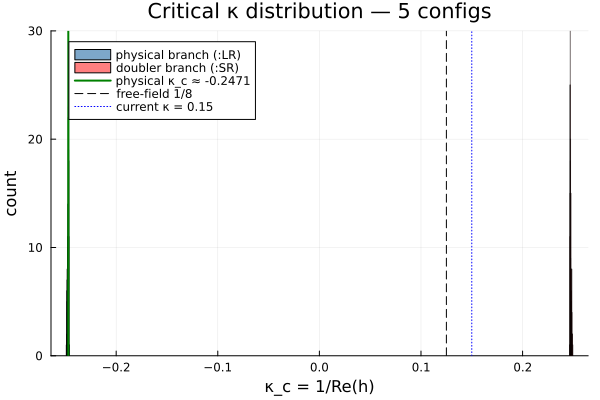

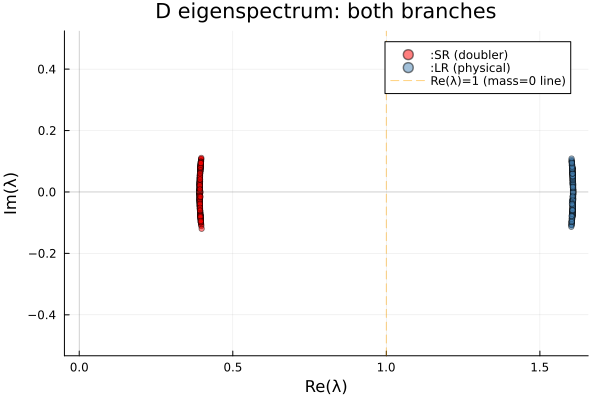

In [12]:
# κ_c 분포 히스토그램
p_kc1 = histogram(κc_LR, bins=40, alpha=0.7, color=:steelblue, label="physical branch (:LR)",
    xlabel="κ_c = 1/Re(h)", ylabel="count",
    title="Critical κ distribution — $(length(gauge_files)) configs")
histogram!(κc_SR, bins=40, alpha=0.5, color=:red, label="doubler branch (:SR)")
vline!([κc_avg], color=:green, linewidth=2, label="physical κ_c ≈ $(round(κc_avg, digits=4))")
vline!([0.125], color=:black, linewidth=1, linestyle=:dash, label="free-field 1/8")
vline!([κ_now], color=:blue, linewidth=1, linestyle=:dot, label="current κ = $κ_now")
display(p_kc1)

# 복소 평면에 :SR과 :LR 모두 표시 + κ_c annotation
all_SR = vcat(all_evals...)
all_LR = vcat(all_evals_LR...)
p_kc2 = scatter(real.(all_SR), imag.(all_SR), markersize=3, alpha=0.5,
    label=":SR (doubler)", color=:red,
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="D eigenspectrum: both branches", aspect_ratio=:equal)
scatter!(real.(all_LR), imag.(all_LR), markersize=3, alpha=0.5,
    label=":LR (physical)", color=:steelblue)
vline!([0], color=:gray, linewidth=1, alpha=0.3, label=nothing)
vline!([1], color=:orange, linewidth=1, linestyle=:dash, alpha=0.5, label="Re(λ)=1 (mass=0 line)")
hline!([0], color=:gray, linewidth=1, alpha=0.3, label=nothing)
display(p_kc2)

## Critical κ — ensemble (β=6, 8³×16)

각 config의 D 고유값에서 `min Re(λ_D)`를 찾아  
$$\kappa_c^{(i)} = \frac{\kappa_{\text{now}}}{1 - \min_j \mathrm{Re}\,\lambda_j^{(i)}}$$  
로 추정. ensemble 평균과 표준오차(SEM)를 계산.


In [13]:
# ensemble κ_c 계산
# - 각 config에서 D의 :SR 고유값 nev_kc개를 구하고
# - κ_c^(i) = κ_now / (1 - min Re λ) 추정

const GAUGE_DIR = "C:\\Users\\_s2220186\\Desktop\\Julia\\heatbath_ensemble_beta6.0"
config_ids   = collect(1:20)              # ← 사용할 config 번호 (조정 가능)
nev_kc       = 8                           # config당 구할 :SR 고유값 개수
κ_now_kc     = params["κ"]
β            = 6.0

κc_list   = Float64[]
λmin_list = Float64[]
used_ids  = Int[]

for cid in config_ids
    gfile = joinpath(GAUGE_DIR, "config_$(cid).jld2")
    if !isfile(gfile)
        @warn "missing $gfile, skip"
        continue
    end
    Ug = load(gfile, "U")
    U  = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)

    xtmp = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W  = Dirac_operator(U, xtmp, params)

    evals, _ = compute_D_eigenvalues(D_W, U, nev_kc;
                  krylovdim=max(2nev_kc + 20, 40), tol=1e-7, maxiter=400)

    λmin = minimum(real.(evals))
    kc   = κ_now_kc / (1 - λmin)
    push!(λmin_list, λmin)
    push!(κc_list,   kc)
    push!(used_ids,  cid)
    println("config $cid: min Re(λ) = $(round(λmin, digits=6)),  κ_c ≈ $(round(kc, digits=6))")
end

N = length(κc_list)
μ_kc  = sum(κc_list) / N
σ_kc  = sqrt(sum((κc_list .- μ_kc).^2) / (N - 1))      # sample std
sem   = σ_kc / sqrt(N)                                 # standard error of mean

# Jackknife (보조 추정)
jk_means = [ (sum(κc_list) - κc_list[i]) / (N - 1) for i in 1:N ]
jk_mean  = sum(jk_means) / N
jk_err   = sqrt((N - 1)/N * sum((jk_means .- jk_mean).^2))

println("\n" * "="^58)
println("  Critical κ (β=$β, lattice $(NX)×$(NY)×$(NZ)×$(NT))")
println("="^58)
println("  N configs                = $N")
println("  ⟨κ_c⟩                    = $(round(μ_kc, digits=6))")
println("  sample std σ             = $(round(σ_kc, digits=6))")
println("  standard error (SEM)     = $(round(sem,  digits=6))")
println("  jackknife mean           = $(round(jk_mean, digits=6))")
println("  jackknife error          = $(round(jk_err,  digits=6))")
println("  → κ_c = $(round(μ_kc, digits=5)) ± $(round(sem, digits=5))   (SEM)")
println("="^58)


KrylovKit: 0 converged, 400 iterations, 6424 matvecs
config 1: min Re(λ) = 0.392266,  κ_c ≈ 0.246819


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (2.87e-02, 2.42e-02, 3.91e-02, 5.73e-02, 5.58e-02, 6.78e-02, 7.40e-02, 6.28e-02)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 0 converged, 400 iterations, 6424 matvecs
config 2: min Re(λ) = 0.392617,  κ_c ≈ 0.246961


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (1.46e-02, 1.73e-02, 4.00e-02, 5.31e-02, 5.83e-02, 4.77e-02, 2.52e-02, 2.52e-02)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 0 converged, 400 iterations, 6424 matvecs
config 3: min Re(λ) = 0.391468,  κ_c ≈ 0.246495


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (6.08e-03, 1.39e-02, 2.19e-02, 5.44e-02, 9.88e-03, 1.72e-02, 6.26e-02, 3.20e-02)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


... (30 outputs left out)

KrylovKit: 0 converged, 400 iterations, 6424 matvecs
config 19: min Re(λ) = 0.390651,  κ_c ≈ 0.246164


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (4.13e-06, 2.53e-02, 4.65e-02, 3.26e-02, 5.60e-02, 5.51e-02, 5.92e-02, 3.28e-02)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


KrylovKit: 0 converged, 400 iterations, 6424 matvecs
config 20: min Re(λ) = 0.391116,  κ_c ≈ 0.246352

  Critical κ (β=6.0, lattice 16×16×16×32)
  N configs                = 20
  ⟨κ_c⟩                    = 0.246649
  sample std σ             = 0.000339
  standard error (SEM)     = 7.6e-5
  jackknife mean           = 0.246649
  jackknife error          = 7.6e-5
  → κ_c = 0.24665 ± 8.0e-5   (SEM)


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (2.56e-03, 9.04e-04, 4.16e-02, 5.79e-02, 5.09e-02, 5.23e-02, 5.49e-02, 5.34e-02)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\nyPcr\src\eigsolve\arnoldi.jl:172


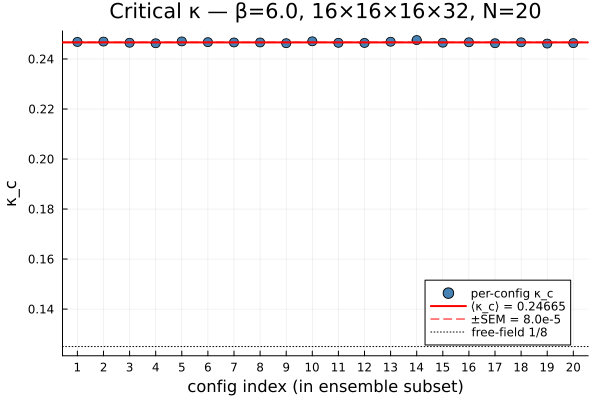

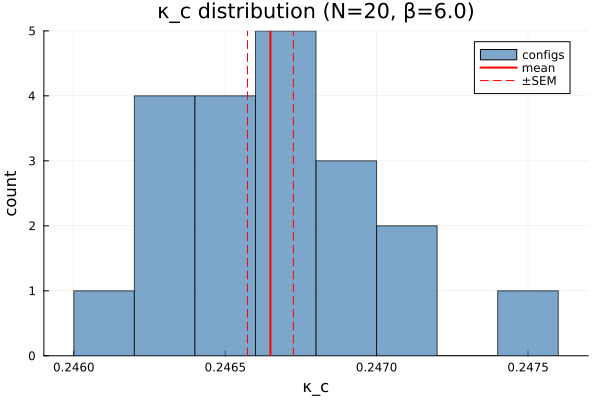

In [14]:
# 시각화: config별 κ_c + 평균/오차 밴드
xs = 1:N

p_kc = scatter(xs, κc_list,
    yerror = fill(0.0, N),                # 개별 점은 단일값 (시각용)
    markersize=5, color=:steelblue, label="per-config κ_c",
    xlabel="config index (in ensemble subset)", ylabel="κ_c",
    title="Critical κ — β=$β, $(NX)×$(NY)×$(NZ)×$(NT), N=$N",
    xticks=(xs, string.(used_ids)))

# 평균선 + ±SEM 밴드
hline!([μ_kc], color=:red, linewidth=2, label="⟨κ_c⟩ = $(round(μ_kc,digits=5))")
hline!([μ_kc + sem, μ_kc - sem], color=:red, linewidth=1, linestyle=:dash, label="±SEM = $(round(sem,digits=5))")

# free-field 기준선
hline!([0.125], color=:black, linewidth=1, linestyle=:dot, label="free-field 1/8")
display(p_kc)

# κ_c 분포 히스토그램
p_kc_hist = histogram(κc_list, bins=max(8, N÷2), alpha=0.7, color=:steelblue,
    xlabel="κ_c", ylabel="count",
    title="κ_c distribution (N=$N, β=$β)",
    label="configs")
vline!([μ_kc], color=:red, linewidth=2, label="mean")
vline!([μ_kc + sem, μ_kc - sem], color=:red, linewidth=1, linestyle=:dash, label="±SEM")
display(p_kc_hist)
